# 17 Quantile forecasts (10% and 90%) at 07:00 and 09:00

The tails are where the value is (D-004). Two questions, with the pinball loss at 10% and 90% as the primary measure:

1. **How good are the 10% and 90% quantile forecasts**, compared with the baseline of notebook 06 (empirical 10%/90% of the same clock time over D-29..D-2, which under-covers: 13.1% below, 13.8% above)? Also their coverage (share of actual prices below the 10% and above the 90% forecast; nominal 10% each).
2. **Does ranking each day's periods by the 90% quantile (top-8) or the 10% quantile (bottom-8) pick the extreme periods better** than ranking by the point forecast?

Split models as decided in notebook 16: 09:00 with demand inputs, 07:00 without. Quantile variants, fixed before running:

| Variant | Construction |
| --- | --- |
| baseline | empirical D-29..D-2 same-clock-time quantiles (notebook 06) |
| Q1 | gradient boosting with quantile loss at tau = 0.1 and 0.9 on the deviation from `ref28`, with the V0 inputs (notebook 14 / 16) |
| Q2 | as Q1, but the target is also net of the daily level (`price - ref28 - L(D)`, with `L(D)` the in-fold fitted anomaly level model of notebook 15), and `L(D)` is added back to the prediction. The level part is then supplied by the model that fixed the late-fold level problem and the quantile model only has to describe the spread around it |
| R (Huber / GBM point forecast) | the two-part point forecast of notebook 16 (`+ level`) plus a constant offset: the 10% and 90% quantiles of its residuals (price minus forecast) on **earlier** validation blocks, all of them (`R all`) or the last three (`R last 3`). The last day of the block immediately before a fold is left out, because its prices would not be complete at the cutoff (gap of one day as in D-007) |

R needs earlier validation blocks, so all variants are scored on folds 1-16 (fold 0 has none). Same rows for every variant (rows where all variants have a value). Dev-only.

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from _common import load, to_uk, dev_only
from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

TT = pd.read_parquet("outputs/feature_table_dev.parquet").reset_index(drop=True)
REF = "med28_same"
days = pd.DatetimeIndex(sorted(TT["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
COMMON = TT[REF].notna() & TT["price"].notna()
TT["ydev"] = TT["price"] - TT[REF]
CUT = {7: TT["cutoff_hour"] == 7, 9: TT["cutoff_hour"] == 9}

# baseline quantiles exactly as in notebook 06
price = dev_only(load("imbalance_price")).set_index("period_start")["price_gbp_per_mwh"]
loc = to_uk(price.index.to_series())
dfp = pd.DataFrame({"price": price, "day": loc.dt.tz_localize(None).dt.normalize(), "hhmm": loc.dt.strftime("%H:%M")})
dfp["occ"] = dfp.groupby(["day", "hhmm"]).cumcount()
wide = dfp.pivot(index="day", columns=["hhmm", "occ"], values="price")
wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max(), freq="D"))
known = wide.shift(2)
def to_long(Fm):
    ri = Fm.index.get_indexer(dfp["day"])
    ci = Fm.columns.get_indexer(pd.MultiIndex.from_frame(dfp[["hhmm", "occ"]]))
    out = np.full(len(dfp), np.nan)
    ok = (ri >= 0) & (ci >= 0)
    out[ok] = Fm.to_numpy()[ri[ok], ci[ok]]
    return pd.Series(out, index=dfp.index)
Qb = pd.DataFrame({"q10": to_long(known.rolling(28, min_periods=14).quantile(0.1)),
                   "q90": to_long(known.rolling(28, min_periods=14).quantile(0.9))})
TT = TT.merge(Qb.rename(columns={"q10": "bq10", "q90": "bq90"}), left_on="period_start", right_index=True, how="left")
CUT = {7: TT["cutoff_hour"] == 7, 9: TT["cutoff_hour"] == 9}
COMMON = TT[REF].notna() & TT["price"].notna()
print(len(TT), "rows;", TT[["bq10", "bq90"]].notna().mean().round(3).to_dict(), "baseline quantile coverage of rows")

64702 rows; {'bq10': 0.978, 'bq90': 0.978} baseline quantile coverage of rows


## 1. Quantile gradient boosting (Q1, Q2)

Same feature lists and hyperparameters as the V0 gradient boosting of notebooks 14 and 16 (300 trees, learning rate 0.05, 15 leaves, 100 rows per leaf, L2 1.0), with the loss changed to the quantile loss. The 07:00 model drops the demand and revision columns, the 09:00 model keeps them.

In [2]:
ABS = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]
ANOM = ["demand_anom", "wind_anom", "emb_wind_anom", "emb_solar_anom"]
HIST = ["med28_same", "med7_same", "d2_same", "level24h", "level7", "level28", "level_gap"]
MGN = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
GBM_EXTRA = ["wind_total_mw", "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev", "is_weekend"]
DEMAND_COLS = {"demand_mw", "demand_age_h", "demand_rev", "demand_anom"}
REV_COLS = {"demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"}
DROP = {9: set(), 7: DEMAND_COLS | REV_COLS}
GCOLS = {c: [x for x in dict.fromkeys(["hour_frac", "weekday", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"] + ABS + MGN + GBM_EXTRA + HIST) if x not in DROP[c]] for c in (7, 9)}

def qgbm(tau):
    return HistGradientBoostingRegressor(loss="quantile", quantile=tau, max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=100, l2_regularization=1.0, early_stopping=False, random_state=0)
def level_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), HuberRegressor(alpha=10, epsilon=1.35, max_iter=300))

dm = TT[COMMON & CUT[9]].groupby("day")["ydev"].agg(["mean", "count"])
DAILY = {}
for c in (7, 9):
    g = TT[CUT[c]].groupby("day")
    d = g[ANOM].mean(); d["is_weekend"] = g["is_weekend"].mean(); d["bank_holiday"] = g["bank_holiday"].mean()
    d["target"] = dm["mean"].where(dm["count"] >= 40).reindex(d.index)
    DAILY[c] = d
LCOLS = {9: ANOM + ["is_weekend", "bank_holiday"], 7: [a for a in ANOM if a != "demand_anom"] + ["is_weekend", "bank_holiday"]}

QP = {}   # (cut, variant, tau) -> Series on TT.index
def run_q(cut):
    for v in ("Q1", "Q2"):
        for tau in (0.1, 0.9):
            QP[(cut, v, tau)] = pd.Series(np.nan, index=TT.index)
    cols = GCOLS[cut]
    for f in folds:
        tr = TT[CUT[cut] & TT["day"].isin(f["train_days"]) & COMMON]
        va = TT[CUT[cut] & TT["day"].isin(f["val_days"])]
        dtr = DAILY[cut].loc[DAILY[cut].index.isin(f["train_days"])]
        lm = level_model().fit(dtr.loc[dtr["target"].notna(), LCOLS[cut]], dtr.loc[dtr["target"].notna(), "target"])
        lt_train = pd.Series(lm.predict(dtr[LCOLS[cut]]), index=dtr.index)          # in-sample fitted level
        dva = DAILY[cut].loc[DAILY[cut].index.isin(f["val_days"])]
        lt_val = pd.Series(lm.predict(dva[LCOLS[cut]]), index=dva.index)
        for tau in (0.1, 0.9):
            QP[(cut, "Q1", tau)].loc[va.index] = va[REF] + qgbm(tau).fit(tr[cols], tr["ydev"]).predict(va[cols])
            m2 = qgbm(tau).fit(tr[cols], tr["ydev"] - tr["day"].map(lt_train).fillna(0.0))
            QP[(cut, "Q2", tau)].loc[va.index] = va[REF] + va["day"].map(lt_val) + m2.predict(va[cols])

t0 = time.time()
for cut in (9, 7):
    run_q(cut); print("cutoff", cut, f"{time.time() - t0:.0f}s")

cutoff 9 73s


cutoff 7 141s


## 2. Residual-offset quantiles (R) around the two-part point forecast

In [3]:
P16 = pd.read_parquet("outputs/cv_preds_cutoffs_0700_0900.parquet")
PT = TT[["period_start", "cutoff_hour"]].merge(P16, on=["period_start", "cutoff_hour"], how="left")
PT.index = TT.index
NAME = {9: "split 09", 7: "split 07"}
RQ = {}   # (cut, variant, tau)
for cut in (9, 7):
    for fam in ("huber", "gbm"):
        pt = PT[f"{fam} | {NAME[cut]} | {cut} | + level"]
        res = (TT["price"] - pt).where(CUT[cut] & COMMON)
        for lab, nlast in (("all", None), ("last 3", 3)):
            for tau in (0.1, 0.9):
                s = pd.Series(np.nan, index=TT.index)
                for f in folds[1:]:
                    k = f["fold"]
                    prev = [folds[j]["val_days"] for j in range(max(0, k - (nlast or k)), k)]
                    prev[-1] = prev[-1][:-1]                         # drop the last day of the preceding block
                    pdays = pd.DatetimeIndex(np.concatenate([p.values for p in prev]))
                    off = res[TT["day"].isin(pdays)].quantile(tau)
                    m = CUT[cut] & TT["day"].isin(f["val_days"])
                    s[m] = pt[m] + off
                RQ[(cut, f"R {fam} {lab}", tau)] = s
print(len(RQ), "residual-offset series built;", "example offsets (fold 16, huber all, 09:00):")
pt = PT["huber | split 09 | 9 | + level"]; res = (TT["price"] - pt).where(CUT[9] & COMMON)
print({tau: round(float((RQ[(9, "R huber all", tau)] - pt).dropna().iloc[-1]), 1) for tau in (0.1, 0.9)})

16 residual-offset series built; example offsets (fold 16, huber all, 09:00):
{0.1: -44.3, 0.9: 41.9}


## 3. Scores

Folds 1-16, same rows for every variant. `pin10`/`pin90`: pinball loss; `below q10` / `above q90`: share of actual prices below the 10% / above the 90% forecast (nominal 0.10); `width`: mean 90%-10% spread. `hit top8 by q90` and `hit bot8 by q10` rank each day's periods by the 90% (10%) quantile instead of the point forecast; point-forecast hit rates are shown next to them.

In [4]:
VARS = {}
for cut in (9, 7):
    VARS[(cut, "baseline")] = (TT["bq10"], TT["bq90"])
    for v in ("Q1", "Q2"):
        VARS[(cut, v)] = (QP[(cut, v, 0.1)], QP[(cut, v, 0.9)])
    for fam in ("huber", "gbm"):
        for lab in ("all", "last 3"):
            VARS[(cut, f"R {fam} {lab}")] = (RQ[(cut, f"R {fam} {lab}", 0.1)], RQ[(cut, f"R {fam} {lab}", 0.9)])
MASK = {}
for cut in (9, 7):
    ok = CUT[cut] & COMMON
    for (c, v), (a, b) in VARS.items():
        if c == cut:
            ok &= a.notna() & b.notna()
    MASK[cut] = ok & TT["day"].isin(pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds[1:]])))
    print(cut, "scored rows:", int(MASK[cut].sum()))

def qscore(cut, q10, q90, pt=None):
    rows = []
    for f in folds[1:]:
        m = MASK[cut] & TT["day"].isin(f["val_days"])
        d = TT.loc[m, ["day", "price"]].assign(q10=q10[m], q90=q90[m])
        s = score(d, "q90", q10="q10", q90="q90")
        r = {"fold": f["fold"], "pin10": s["pinball10"], "pin90": s["pinball90"], "hit top8 by q90": s["hit_top8"],
             "hit bot8 by q10": score(d, "q10")["hit_bot8"],
             "below q10": (d["price"] < d["q10"]).mean(), "above q90": (d["price"] > d["q90"]).mean(),
             "width": (d["q90"] - d["q10"]).mean()}
        if pt is not None:
            sp = score(d.assign(pt=pt[m]), "pt"); r["hit top8 point"] = sp["hit_top8"]; r["hit bot8 point"] = sp["hit_bot8"]
        rows.append(r)
    return pd.DataFrame(rows).set_index("fold")

QF = {}
for cut in (9, 7):
    for (c, v), (a, b) in VARS.items():
        if c == cut:
            QF[(c, v)] = qscore(cut, a, b)
    for fam in ("huber", "gbm"):
        pt = PT[f"{fam} | {NAME[cut]} | {cut} | + level"]
        QF[(cut, f"point {fam}")] = qscore(cut, VARS[(cut, "baseline")][0], VARS[(cut, "baseline")][1], pt)

def summ(ft):
    return {"pin10": ft["pin10"].mean(), "pin90": ft["pin90"].mean(), "pin10 late": ft["pin10"].loc[13:].mean(), "pin90 late": ft["pin90"].loc[13:].mean(),
            "below q10": ft["below q10"].mean(), "above q90": ft["above q90"].mean(), "below late": ft["below q10"].loc[13:].mean(), "above late": ft["above q90"].loc[13:].mean(),
            "width": ft["width"].mean(), "hit top8 by q90": ft["hit top8 by q90"].mean(), "hit bot8 by q10": ft["hit bot8 by q10"].mean()}
for cut in (9, 7):
    print(f"{cut:02d}:00")
    print(pd.DataFrame({v: summ(QF[(c, v)]) for (c, v) in QF if c == cut and not v.startswith("point")}).T.round(3).to_string())
    print("point forecast hit rates (rank by the point forecast), same rows:",
          {fam: (round(QF[(cut, f"point {fam}")]["hit top8 point"].mean(), 3), round(QF[(cut, f"point {fam}")]["hit bot8 point"].mean(), 3)) for fam in ("huber", "gbm")})
    print()

9 scored rows: 21501
7 scored rows: 21501


09:00
                pin10  pin90  pin10 late  pin90 late  below q10  above q90  below late  above late   width  hit top8 by q90  hit bot8 by q10
baseline        8.243  6.373       8.480       6.750      0.131      0.138       0.095       0.152  85.935            0.459            0.326
Q1              5.821  6.519       6.385       7.799      0.123      0.187       0.057       0.275  72.524            0.471            0.358
Q2              5.894  6.390       6.390       7.538      0.133      0.172       0.063       0.252  74.161            0.468            0.362
R huber all     6.867  6.140       7.272       6.761      0.099      0.109       0.102       0.131  87.368            0.493            0.376
R huber last 3  6.951  6.160       7.264       6.783      0.107      0.110       0.084       0.109  85.873            0.493            0.376
R gbm all       6.821  6.349       7.098       6.862      0.099      0.106       0.108       0.129  87.177            0.485            0.360
R gbm l

## 4. Paired against the baseline quantiles

Mean per-fold difference in pinball loss (negative is better) +/- standard error over the 16 folds, and over the late folds 13-16; and the number of folds (of 16) better than the baseline. The folds are adjacent, so standard errors are optimistic.

In [5]:
rows = {}
for cut in (9, 7):
    b = QF[(cut, "baseline")]
    for (c, v), ft in QF.items():
        if c != cut or v in ("baseline",) or v.startswith("point"):
            continue
        r = {}
        for m in ("pin10", "pin90"):
            d = ft[m] - b[m]
            r[f"d{m}"] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(16):.3f}"; r[f"d{m} late"] = f"{d.loc[13:].mean():+.3f}"; r[f"{m} folds better"] = int((d < 0).sum())
        rows[f"{cut:02d}:00 {v}"] = r
print(pd.DataFrame(rows).T.to_string())

                                dpin10 dpin10 late pin10 folds better            dpin90 dpin90 late pin90 folds better
09:00 Q1              -2.422 +/- 0.414      -2.095                 15  +0.146 +/- 0.260      +1.049                  8
09:00 Q2              -2.349 +/- 0.413      -2.090                 15  +0.017 +/- 0.230      +0.788                  5
09:00 R huber all     -1.376 +/- 0.370      -1.209                 13  -0.233 +/- 0.203      +0.011                 11
09:00 R huber last 3  -1.292 +/- 0.373      -1.216                 12  -0.213 +/- 0.185      +0.033                 10
09:00 R gbm all       -1.422 +/- 0.363      -1.382                 13  -0.024 +/- 0.220      +0.113                  7
09:00 R gbm last 3    -1.343 +/- 0.366      -1.400                 12  +0.004 +/- 0.190      +0.128                  8
07:00 Q1              -2.314 +/- 0.426      -1.928                 14  +0.136 +/- 0.226      +0.721                  8
07:00 Q2              -2.275 +/- 0.430      -1.9

## 5. Coverage by fold (Q2, 09:00 and 07:00) against the baseline

Share of actual prices below the 10% forecast and above the 90% forecast, per fold.

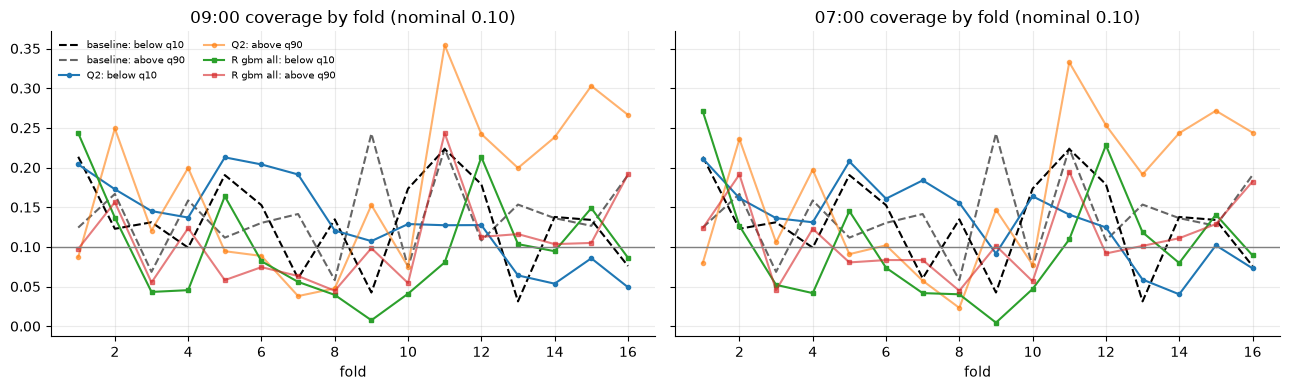

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cut in zip(axes, (9, 7)):
    for v, st in (("baseline", "k--"), ("Q2", "-o"), ("R gbm all", "-s")):
        ft = QF[(cut, v)]
        ax.plot(ft["below q10"], st, ms=3, label=f"{v}: below q10")
        ax.plot(ft["above q90"], st, ms=3, alpha=0.6, label=f"{v}: above q90")
    ax.axhline(0.1, color="grey", lw=1); ax.set_title(f"{cut:02d}:00 coverage by fold (nominal 0.10)"); ax.set_xlabel("fold")
axes[0].legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 6. Tail ranking

In the table of section 3, `hit top8 by q90` and `hit bot8 by q10` can be compared with the point-forecast hit rates printed under it (same rows). Paired differences over folds, ranking by the quantile minus ranking by the point forecast of the GBM family (Q2 at 09:00 and 07:00).

In [7]:
rows = {}
for cut in (9, 7):
    pf = QF[(cut, "point gbm")]
    for v in ("Q1", "Q2", "baseline"):
        q = QF[(cut, v)]
        r = {}
        for a, b, lab in (("hit top8 by q90", "hit top8 point", "top-8: q90 minus point"), ("hit bot8 by q10", "hit bot8 point", "bottom-8: q10 minus point")):
            d = q[a] - pf[b]
            r[lab] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(16):.3f}"; r[lab + " late"] = f"{d.loc[13:].mean():+.3f}"
        rows[f"{cut:02d}:00 {v}"] = r
print(pd.DataFrame(rows).T.to_string())

out = pd.DataFrame(index=TT.index)
for (c, v, t), s in list(QP.items()) + list(RQ.items()):
    out[f"{c} | {v} | q{int(t * 100)}"] = s
for c in ["day", "period_start", "cutoff_hour", "price", REF, "bq10", "bq90"]:
    out[c] = TT[c]
out[out["day"].isin(val_days_all)].to_parquet("outputs/cv_quantiles_0700_0900.parquet", index=False)

               top-8: q90 minus point top-8: q90 minus point late bottom-8: q10 minus point bottom-8: q10 minus point late
09:00 Q1             -0.014 +/- 0.008                      -0.002          -0.003 +/- 0.012                         +0.017
09:00 Q2             -0.017 +/- 0.007                      +0.002          +0.002 +/- 0.010                         +0.020
09:00 baseline       -0.026 +/- 0.010                      -0.017          -0.034 +/- 0.017                         +0.012
07:00 Q1             -0.008 +/- 0.007                      +0.010          -0.006 +/- 0.010                         +0.021
07:00 Q2             -0.020 +/- 0.006                      -0.004          -0.012 +/- 0.009                         +0.001
07:00 baseline       -0.020 +/- 0.012                      -0.006          -0.030 +/- 0.014                         +0.033


## Findings (folds 1-16, same rows for every variant; variants fixed before running; baseline pinball 8.24 at 10% and 6.37 at 90%, identical at both cutoffs)

- **The lower quantile (10%) is clearly predictable; the upper (90%) is not, yet.** At 09:00 the quantile GBM Q1 lowers the 10% pinball by -2.42 +/- 0.41 (better in 15 of 16 folds) and Q2 by -2.35 +/- 0.41 (15 of 16); at 07:00 -2.31 and -2.28 (14 and 13 of 16). The residual-offset variants (R) help less (-1.0 to -1.4). At the 90% quantile none of the variants beats the baseline reliably: Q1 +0.15 +/- 0.26, Q2 +0.02 +/- 0.23 at 09:00, and in the late folds (13-16) they are worse (+1.05 and +0.79); R Huber (all earlier blocks) is the best at 90%: -0.23 +/- 0.20 (11 of 16), late +0.01.
- **Calibration explains the 90% result.** The quantile GBMs are too low in the recent high-price folds: in folds 13-16 actual prices exceed the 90% forecast 27.5% (Q1) and 25.2% (Q2) of the time at 09:00 (baseline 15.2%), and fall below the 10% forecast 5.7% / 6.3% of the time (nominal 10%). This is the same effect as the point-forecast under-forecast in notebooks 10-13: a model trained on the past does not follow a rising price level in its upper tail. Q2 (level supplied by the anomaly level model) only reduces this a little (27.5% to 25.2%). Over all folds: Q1 0.123 below / 0.187 above, Q2 0.133 / 0.172, baseline 0.131 / 0.138, R Huber 0.099 / 0.109 (the best calibrated overall and in the late folds: 0.102 / 0.131).
- **R, the point forecast with offsets from earlier residuals, is the better calibrated; the quantile GBM is the sharper at the bottom.** The R forecasts are as wide as the baseline (width 87 against 86) but centred better; Q1/Q2 are narrower (72-74 against 86). Using the last three blocks instead of all earlier blocks makes no difference to pinball (within 0.1) and slightly improves the late-fold upper coverage (R Huber 0.109 against 0.131 above q90 over the late folds).
- **Cutoff.** 07:00 pinball is a little worse than 09:00 for the same variant (10%: 5.97 against 5.89 for Q2; 90%: 6.45 against 6.39), consistent with notebook 16: demand matters little for the quantiles.
- **Ranking by the quantiles does not beat ranking by the point forecast.** Rank by the 90% quantile for top-8 and the 10% quantile for bottom-8, minus the point-forecast (GBM) hit rate: top-8 -0.014 +/- 0.008 (Q1), -0.017 +/- 0.007 (Q2) at 09:00, -0.008 and -0.020 at 07:00; bottom-8 within +/-0.012 of zero (late folds about +0.02 for Q1/Q2 at 09:00 on four folds only). The baseline quantiles rank worse than the baseline point forecast (-0.03). So the quantile models are a calibration/uncertainty product and not a better ranking tool; the point forecast stays the ranking.
- **What this suggests (not tested).** Take the 10% forecast from a quantile model (Q1 or Q2) and the 90% from the point forecast plus residual offsets (R Huber). That combination was not specified in advance, so it needs to be treated as a candidate to confirm on the hold-out, not as a result.
- **Caveats.** (1) The R variants use the notebook-16 point forecasts, which carry the design caveat of notebooks 13-15; the quantile GBMs (Q1/Q2) were specified from scratch. (2) The GBM is deterministic (seed irrelevant, notebook 18); 16 adjacent folds (standard errors optimistic); the late-fold statements rest on four folds. (3) Q2's training level is the in-sample fit of the level model, slightly closer to the data than an out-of-sample level. (4) Only 10% and 90% were evaluated, as two separate models; the 10% forecast is never above the 90% forecast (crossing share 0.0 for Q1 and Q2 at both cutoffs). (5) Pinball at 90% is dominated by few very high prices; its fold-to-fold spread is large (standard errors 0.2-0.26 on a mean of 6.4).
